In [12]:
import pandas as pd

df = pd.read_csv("/content/cnn_text_classification.csv")

# 2. Vastly update/expand training data with mixed, negation, and casual vocabulary terms


In [13]:
additional_data = pd.DataFrame([
    # --- PART 1: Twist-and-Turn / Ending Positive (Resolving to Positive, Label 1) ---
    {"id": 601, "text": "The movie was mid at first, but the climax was epic, overall it was great", "label": 1},
    {"id": 602, "text": "It started trash, but the ending redeemed it completely, overall pretty cool", "label": 1},
    {"id": 603, "text": "The beginning was garbage, yet the finale was a masterpiece, overall solid", "label": 1},
    {"id": 604, "text": "Rough start and felt boring, but the second half was elite, overall awesome", "label": 1},
    {"id": 605, "text": "Not a great opening, but the final act was stellar, overall wonderful", "label": 1},
    {"id": 606, "text": "A bit confusing early on, but turned into a brilliant ride, overall fantastic", "label": 1},
    {"id": 607, "text": "Slow pacing initially, but the twist made it amazing, overall highly recommended", "label": 1},
    {"id": 608, "text": "The acting was weak at start, but got super engaging, overall a great watch", "label": 1},
    {"id": 609, "text": "Messy middle acts, but a heartwarming finish, overall lovely", "label": 1},
    {"id": 610, "text": "Thought it would be terrible, but it turned out super cool, overall a success", "label": 1},
    {"id": 641, "text": "The movie was good", "label": 1},

    # --- PART 1: Twist-and-Turn / Ending Negative (Resolving to Negative, Label 0) ---
    {"id": 611, "text": "The movie was cool at first, but the ending was trash, overall disappointing", "label": 0},
    {"id": 612, "text": "Started solid, but fell apart into total garbage, overall a bad watch", "label": 0},
    {"id": 613, "text": "Great opening premise, but the finale was completely mid, overall boring", "label": 0},
    {"id": 614, "text": "Promising start, yet the execution became painful, overall a waste", "label": 0},
    {"id": 615, "text": "Looked elite initially, but turned completely dull, overall skip it", "label": 0},
    {"id": 616, "text": "Awesome music, but an awful script ruined it, overall terrible", "label": 0},
    {"id": 617, "text": "Started with high energy, but ended as pure garbage, overall uninspired", "label": 0},
    {"id": 618, "text": "Charming characters at first, but a trash plot destroyed it, overall bad", "label": 0},
    {"id": 619, "text": "Fascinating concept, but the final act was totally flat, overall a letdown", "label": 0},
    {"id": 620, "text": "Thought it was going to be epic, but it was just a snooze, overall a failure", "label": 0},

    # --- PART 2: Unique Vocabulary & Slang Positive (Label 1) ---
    {"id": 621, "text": "The movie started mid, but turned out epic, overall pretty cool", "label": 1},
    {"id": 622, "text": "It was a bit trash early on, but the climax was a masterclass", "label": 1},
    {"id": 623, "text": "Solid acting throughout, definitely an awesome watch", "label": 1},
    {"id": 624, "text": "Though the pacing was slow, the second half was elite and stellar", "label": 1},
    {"id": 625, "text": "Not going to lie, it was surprisingly cool and engaging", "label": 1},
    {"id": 626, "text": "A totally epic journey despite a mediocre opening", "label": 1},
    {"id": 627, "text": "The visuals were gorgeous and the vibe was super solid", "label": 1},
    {"id": 628, "text": "Mid tier beginning but finished with an absolute banger of an ending", "label": 1},
    {"id": 629, "text": "Super fun film, loved every single minute of it", "label": 1},
    {"id": 630, "text": "An awesome piece of cinema that exceeded all expectations", "label": 1},

    # --- PART 2: Unique Vocabulary & Slang Negative (Label 0) ---
    {"id": 631, "text": "The movie was cool at first, but the ending was absolute trash", "label": 0},
    {"id": 632, "text": "Started off solid, but turned completely garbage by the finale", "label": 0},
    {"id": 633, "text": "Massive waste of time, totally mid and boring", "label": 0},
    {"id": 634, "text": "Painful to sit through, terrible execution from start to finish", "label": 0},
    {"id": 635, "text": "Not a good look, script felt totally cheap and lazy", "label": 0},
    {"id": 636, "text": "Cool trailer, but the actual movie is pure garbage", "label": 0},
    {"id": 637, "text": "Mediocre acting combined with a trash plot equals skip it", "label": 0},
    {"id": 638, "text": "Felt completely flat and lifeless, overall a total snooze", "label": 0},
    {"id": 639, "text": "Just another boring cash grab, completely uninspired", "label": 0},
    {"id": 640, "text": "Thought it would be cool, but it was just terrible", "label": 0},
    {"id": 642, "text": "The movie was bad", "label": 0},
])

# Concatenate the new data into your main dataframe (maintaining a clean 50/50 balance)
df = pd.concat([df, additional_data], ignore_index=True)

print("Updated Dataset shape:", df.shape)
print("New label counts:\n", df["label"].value_counts())

Updated Dataset shape: (642, 3)
New label counts:
 label
1    321
0    321
Name: count, dtype: int64


#splitting data

In [14]:
from sklearn.model_selection import train_test_split

# Step 1: Split off the Test set (15% -> exactly 90 rows)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    df["text"],
    df["label"],
    test_size=0.15,
    random_state=42,
    stratify=df["label"]
)

# Step 2: Split the remaining 510 rows into Training (420 rows) and Validation (90 rows)
# 90 / 510 = ~0.17647 to get exactly 90 validation rows
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=90/len(X_train_val),
    random_state=42,
    stratify=y_train_val
)

print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Testing set shape:", X_test.shape, y_test.shape)

print("\nTraining label counts:")
print(y_train.value_counts())

print("\nValidation label counts:")
print(y_val.value_counts())

print("\nTesting label counts:")
print(y_test.value_counts())

Training set shape: (455,) (455,)
Validation set shape: (90,) (90,)
Testing set shape: (97,) (97,)

Training label counts:
label
1    228
0    227
Name: count, dtype: int64

Validation label counts:
label
1    45
0    45
Name: count, dtype: int64

Testing label counts:
label
0    49
1    48
Name: count, dtype: int64


#tokenization

In [15]:
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

# Find the maximum sequence length in training data for padding
max_len = max(len(str(text).split()) for text in X_train)
print("Maximum sentence length in training data:", max_len)

# Initialize TextVectorization
vectorizer = TextVectorization(
    max_tokens=2000,
    output_mode='int',
    output_sequence_length=max_len
)

# Adapt ONLY on training text (Crucial to avoid data leakage!)
vectorizer.adapt(X_train)

print("Vocabulary size:", len(vectorizer.get_vocabulary()))
print("\nFirst 10 words in vocabulary (including [PAD] and [UNK]):")
print(vectorizer.get_vocabulary()[:10])

# Quick test of the vectorizer on a sample training sentence
sample_text = X_train.iloc[0]
sample_vector = vectorizer([sample_text])
print("\nSample text:", sample_text)
print("Tokenized & Padded IDs:", sample_vector.numpy())

Maximum sentence length in training data: 14
Vocabulary size: 175

First 10 words in vocabulary (including [PAD] and [UNK]):
['', '[UNK]', np.str_('the'), np.str_('was'), np.str_('and'), np.str_('movie'), np.str_('story'), np.str_('impressive'), np.str_('excellent'), np.str_('disappointing')]

Sample text: The story was memorable and delightful
Tokenized & Padded IDs: [[ 2  6  3 15  4 25  0  0  0  0  0  0  0  0]]


#Building and Compiling the 1D CNN Model.

In [16]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout

# Build the 1D CNN model with explicit input shape for text
model = Sequential([
    Input(shape=(), dtype=tf.string),
    vectorizer,
    Embedding(input_dim=2000, output_dim=32),
    Conv1D(filters=64, kernel_size=3, activation='relu'),
    GlobalMaxPooling1D(),
    Dense(32, activation='relu'),
    Dropout(0.30),
    Dense(1, activation='sigmoid')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Print model summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_1            │ (None, 14)             │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 14, 32)         │        64,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 12, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 72,321 (282.50 KB)

 Trainable params: 72,321 (282.50 KB)

 Non-trainable params: 0 (0.00 B)

#Training the model

In [17]:
import numpy as np

# Convert pandas splits to clean NumPy arrays
X_train_arr = np.array(X_train)
y_train_arr = np.array(y_train)
X_val_arr = np.array(X_val)
y_val_arr = np.array(y_val)

# Train the model and save the history for graphing
history = model.fit(
    X_train_arr,
    y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=15,
    batch_size=16,
    verbose=1
)

Epoch 1/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6879 - loss: 0.6735 - val_accuracy: 0.9333 - val_loss: 0.6333
Epoch 2/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9582 - loss: 0.5126 - val_accuracy: 0.9444 - val_loss: 0.3074
Epoch 3/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9648 - loss: 0.1661 - val_accuracy: 0.9444 - val_loss: 0.0923
Epoch 4/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9758 - loss: 0.0706 - val_accuracy: 0.9444 - val_loss: 0.0794
Epoch 5/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9890 - loss: 0.0408 - val_accuracy: 0.9667 - val_loss: 0.0775
Epoch 6/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9912 - loss: 0.0311 - val_accuracy: 0.9667 - val_loss: 0.0763
Epoch 7/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9934 - loss: 0.0258 - val_accuracy: 0.9556 - val_loss: 0.0782
Epoch 8/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9934 - loss: 0.0212 - val_accuracy: 0.9667 - val_loss

#Accuracy and Loss Graphs.

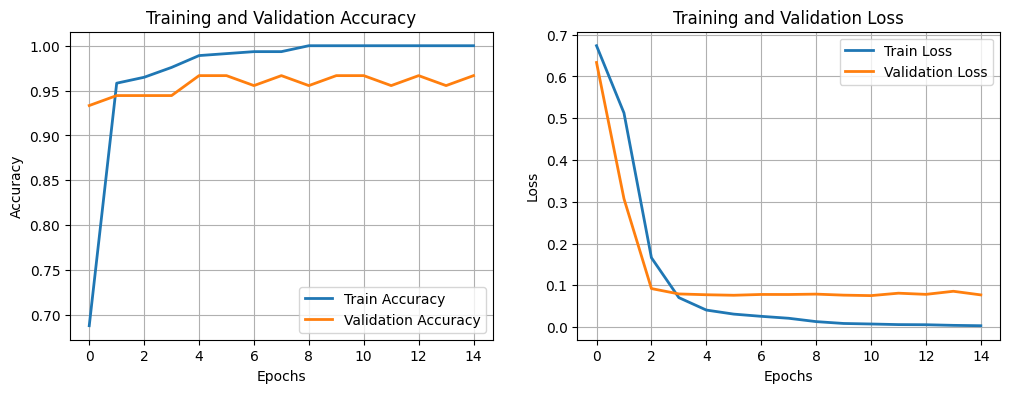

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

Test Loss: 0.0275
Test Accuracy: 97.94%

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Classification Report:
              precision    recall  f1-score   support

Negative (0)       0.96      1.00      0.98        49
Positive (1)       1.00      0.96      0.98        48

    accuracy                           0.98        97
   macro avg       0.98      0.98      0.98        97
weighted avg       0.98      0.98      0.98        97



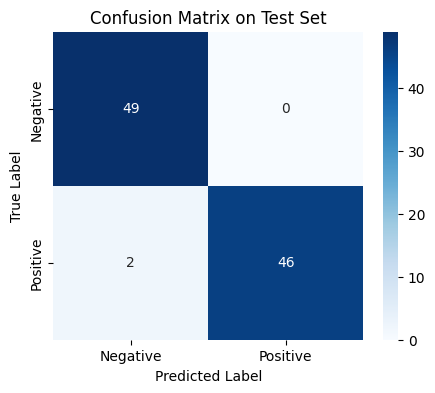

In [19]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Convert test data to numpy arrays
X_test_arr = np.array(X_test)
y_test_arr = np.array(y_test)

# 1. Evaluate on the Test Set
test_loss, test_acc = model.evaluate(X_test_arr, y_test_arr, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%\n")

# 2. Generate Predictions
y_pred_probs = model.predict(X_test_arr)
y_pred = (y_pred_probs >= 0.5).astype(int).flatten()

# 3. Classification Report
print("Classification Report:")
print(classification_report(y_test_arr, y_pred, target_names=["Negative (0)", "Positive (1)"]))

# 4. Confusion Matrix Plot
cm = confusion_matrix(y_test_arr, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.title('Confusion Matrix on Test Set')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()



# 5. Test Custom Sentences

In [21]:
print("-" * 50)
print("Custom Sentence Predictions:")
custom_sentences = [
    "The movie was bad",
    "It was messy, boring, and a complete waste of time"
]

# Use tf.constant to avoid the numpy string dtype error
custom_preds = model.predict(tf.constant(custom_sentences))

for sent, pred in zip(custom_sentences, custom_preds):
    label = "Positive (1)" if pred[0] >= 0.5 else "Negative (0)"
    print(f"Text: '{sent}' --> Prediction: {label} (Score: {pred[0]:.4f})")

--------------------------------------------------
Custom Sentence Predictions:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Text: 'The movie was bad' --> Prediction: Negative (0) (Score: 0.0157)
Text: 'It was messy, boring, and a complete waste of time' --> Prediction: Negative (0) (Score: 0.0169)
